# Dataset Diagnostics: Synthetic Wu 2024 Nonadditive

This notebook inspects the synthetic benchmark used in the experiments: `wu2024_nonadditive` with `single_peaked_heterogeneous` structure. It plots patient-specific and population-level reference curves from the simulator, without fitting any model.

In [19]:
%matplotlib inline

In [20]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import ExperimentConfig
from src.data.factory import make_simulator

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 240)
pd.set_option("display.expand_frame_repr", False)

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.edgecolor"] = "white"

## Configuration

Edit `PATIENT_ID` to select a patient from the chosen split. `POPULATION_N = None` averages over the full selected split; set a smaller integer for faster exploratory runs.

In [21]:
SEED = 10
SPLIT = "test"  # "train" or "test"
N_TRAIN = 3000
N_TEST = 1000
TREATMENT_GRID_SIZE = 51
PATIENT_ID = 0
POPULATION_N = None  # Use None for all rows in the selected split.

# Monte Carlo controls. None uses the simulator defaults.
CAUSAL_MC_SAMPLES = None
CAUSAL_MC_BATCH_SIZE = None
ASSOCIATIONAL_MC_SAMPLES = None
ASSOCIATIONAL_METHOD = None

# Plot controls.
SHOW_GROUND_TRUTH = True
SHOW_ASSOCIATIONAL = True
SHOW_STRUCTURAL = False
SHOW_LEGEND = True
LEGEND_LOC = "best"
LEGEND_BBOX_TO_ANCHOR = None  # Example for an outside legend: (1.02, 1.0)
LEGEND_NCOL = 1
LEGEND_FRAMEON = True

DATASET_VERSION = "wu2024_nonadditive"
STRUCTURE_TYPE = "single_peaked_heterogeneous"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "dataset_diagnostics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## Build Simulator And Sample

The reference values match the synthetic DGP described in the dataset details document: the outcome confounding scale is `1.2` and the nonadditive hidden-confounding scale is `0.7`.

In [22]:
config = ExperimentConfig()
config.seed = int(SEED)
config.data.version = DATASET_VERSION
config.data.structure_type = STRUCTURE_TYPE
config.data.n_train = int(N_TRAIN)
config.data.n_test = int(N_TEST)
config.data.policy_grid_size = int(TREATMENT_GRID_SIZE)
config.data.outcome_confounding_scale = 1.2
config.data.nonadditive_confounding_gamma = 0.7

simulator = make_simulator(config.data)
train_sample, test_sample = simulator.sample_train_test(seed=int(SEED))
sample = train_sample if SPLIT == "train" else test_sample
treatment_grid = np.asarray(simulator.policy_grid, dtype=float).reshape(-1)

print(f"Dataset: {config.data.version} | structure: {config.data.structure_type}")
print(f"Support: {simulator.support}")
print(f"Selected split: {SPLIT} | n={sample.covariates.shape[0]}")
print(f"Treatment grid points: {treatment_grid.shape[0]}")

Dataset: wu2024_nonadditive | structure: single_peaked_heterogeneous
Support: (-1.3675711516196682, 2.356990091265644)
Selected split: test | n=1000
Treatment grid points: 51


## Helper Functions

In [23]:
CURVE_LABELS = {
    "ground_truth_causal": r"$E[Y(a)\mid x]$",
    "associational": r"$E[Y\mid x,a]$",
    "structural": r"$g_{struct}(a,x_i)$: outcome without hidden-confounding term",
    "population_ground_truth_causal": r"$E_X\{E[Y(a)\mid X]\}=E[Y(a)]$",
    "population_associational": r"$E_X\{E[Y\mid X,a]\}$",
    "population_structural": r"$E_X\{g_{struct}(a,X)\}$",
}

CURVE_STYLES = {
    # "ground_truth_causal": {"color": "#1f77b4", "linestyle": "-"},
    # "associational": {"color": "#d62728", "linestyle": "--"},
    "structural": {"color": "#2ca02c", "linestyle": ":"},
    "ground_truth_causal": {"color": "black", "linewidth": 2.4, "linestyle": "-"},
    "associational": {"color": "tab:brown", "linewidth": 2.0, "linestyle": ":"},

    "population_ground_truth_causal": {"color": "black", "linewidth": 2.4, "linestyle": "-"},
    "population_associational": {"color": "tab:brown", "linewidth": 2.0, "linestyle": ":"},
    "population_structural": {"color": "#2ca02c", "linestyle": ":"},
}


def _curve_optimum(treatment_grid: np.ndarray, values: np.ndarray) -> tuple[float, float]:
    idx = int(np.nanargmax(values))
    return float(treatment_grid[idx]), float(values[idx])


def _sample_vector(name: str, patient_id: int) -> float:
    value = getattr(sample, name)
    return float(np.asarray(value).reshape(-1)[patient_id])


def _structural_curve_for_x(x_row: np.ndarray, treatment_grid: np.ndarray) -> np.ndarray:
    x_rep = np.repeat(np.asarray(x_row, dtype=float).reshape(1, -1), len(treatment_grid), axis=0)
    return np.asarray(simulator.mean_outcome(treatment_grid, x_rep), dtype=float).reshape(-1)


def patient_reference_curves(patient_id: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    x_row = sample.covariates[patient_id]
    causal_grid, causal = simulator.causal_curve_given_x_mc(
        x_row,
        grid=treatment_grid,
        n_mc_samples=CAUSAL_MC_SAMPLES,
        batch_size=CAUSAL_MC_BATCH_SIZE,
    )
    (
        assoc_grid,
        associational,
        bin_counts,
        low_count_mask,
        empty_bin_mask,
        empty_fallback_treatment,
        empty_fallback_outcome,
        associational_method,
    ) = simulator.associational_curve_given_x(
        x_row,
        grid=treatment_grid,
        n_mc_samples=ASSOCIATIONAL_MC_SAMPLES,
        method=ASSOCIATIONAL_METHOD,
    )
    causal_grid = np.asarray(causal_grid, dtype=float).reshape(-1)
    assoc_grid = np.asarray(assoc_grid, dtype=float).reshape(-1)
    if not np.allclose(causal_grid, assoc_grid):
        raise RuntimeError("Causal and associational curves were evaluated on different treatment grids.")
    structural = _structural_curve_for_x(x_row, causal_grid)
    curves = pd.concat(
        [
            pd.DataFrame({"patient_id": patient_id, "treatment": causal_grid, "value": np.asarray(causal, dtype=float).reshape(-1), "curve_type": "ground_truth_causal"}),
            pd.DataFrame({"patient_id": patient_id, "treatment": assoc_grid, "value": np.asarray(associational, dtype=float).reshape(-1), "curve_type": "associational"}),
            pd.DataFrame({"patient_id": patient_id, "treatment": causal_grid, "value": structural, "curve_type": "structural"}),
        ],
        ignore_index=True,
    )
    metadata = pd.DataFrame(
        [
            {
                "split": SPLIT,
                "patient_id": patient_id,
                "observed_treatment": _sample_vector("treatment", patient_id),
                "observed_outcome": _sample_vector("outcome", patient_id),
                "optimal_treatment": _sample_vector("optimal_treatment", patient_id),
                "assignment_mean": _sample_vector("assignment_mean", patient_id),
                "associational_method": associational_method,
                "min_associational_count": int(np.nanmin(bin_counts)),
                "n_low_count_associational_points": int(np.sum(low_count_mask)),
                "n_empty_associational_points": int(np.sum(empty_bin_mask)),
            }
        ]
    )
    return curves, metadata


def population_reference_curves(n_patients: int | None = None) -> pd.DataFrame:
    x_eval = sample.covariates if n_patients is None else sample.covariates[:n_patients]
    patient_curves = []
    for patient_id in range(len(x_eval)):
        curves_i, _ = patient_reference_curves(patient_id)
        patient_curves.append(curves_i)
    curves = pd.concat(patient_curves, ignore_index=True)
    grouped = curves.groupby(["curve_type", "treatment"], as_index=False)["value"]
    population = grouped.agg(value="mean", std="std", n="count")
    z_975 = 1.959963984540054
    se = population["std"].fillna(0.0) / np.sqrt(population["n"].clip(lower=1))
    population["ci_lower"] = population["value"] - z_975 * se
    population["ci_upper"] = population["value"] + z_975 * se
    population["curve_type"] = "population_" + population["curve_type"]
    return population


def _selected_curve_types(show_ground_truth: bool, show_associational: bool, show_structural: bool) -> set[str]:
    flags = {
        "ground_truth_causal": show_ground_truth,
        "population_ground_truth_causal": show_ground_truth,
        "associational": show_associational,
        "population_associational": show_associational,
        "structural": show_structural,
        "population_structural": show_structural,
    }
    return {curve_type for curve_type, enabled in flags.items() if enabled}


def _style_reference_axes(ax: plt.Axes) -> None:
    ax.set_facecolor("white")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.0)
    ax.tick_params(axis="both", colors="black", which="both")
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    ax.title.set_color("black")
    ax.grid(True, alpha=0.25, color="#b0b0b0")


def plot_reference_curves(
    curves: pd.DataFrame,
    title: str,
    *,
    show_ground_truth: bool = True,
    show_associational: bool = True,
    show_structural: bool = True,
    show_legend: bool = True,
    legend_loc: str = "best",
    legend_bbox_to_anchor: tuple[float, float] | None = None,
    legend_ncol: int = 1,
    legend_frameon: bool = True,
    show_confidence_intervals: bool = True,
    ci_alpha: float = 0.15,
) -> tuple[plt.Figure, plt.Axes]:
    selected_curve_types = _selected_curve_types(show_ground_truth, show_associational, show_structural)
    curves_to_plot = curves[curves["curve_type"].isin(selected_curve_types)].copy()
    if curves_to_plot.empty:
        raise ValueError("At least one curve must be selected for plotting.")

    fig, ax = plt.subplots(facecolor="white")
    fig.patch.set_facecolor("white")
    for curve_type, group in curves_to_plot.groupby("curve_type", sort=False):
        group = group.sort_values("treatment")
        style = CURVE_STYLES.get(curve_type, {})
        label = CURVE_LABELS.get(curve_type, curve_type)
        treatment = group["treatment"].to_numpy(dtype=float)
        value = group["value"].to_numpy(dtype=float)
        ax.plot(treatment, value, label=label, **style)
        if show_confidence_intervals and {"ci_lower", "ci_upper"}.issubset(group.columns):
            ci_lower = group["ci_lower"].to_numpy(dtype=float)
            ci_upper = group["ci_upper"].to_numpy(dtype=float)
            finite_ci = np.isfinite(ci_lower) & np.isfinite(ci_upper)
            if np.any(finite_ci):
                ax.fill_between(
                    treatment[finite_ci],
                    ci_lower[finite_ci],
                    ci_upper[finite_ci],
                    color=style.get("color", "black"),
                    alpha=ci_alpha,
                    linewidth=0,
                )
        opt_a, opt_y = _curve_optimum(treatment, value)
        ax.scatter([opt_a], [opt_y], marker="*", s=90, color=style.get("color", "black"), edgecolor="black", linewidth=0.1, zorder=7)

    ax.set_xlabel("Treatment")
    ax.set_ylabel("Outcome")
    _style_reference_axes(ax)
    ax.set_ylim([-5,2])
    ax.set_xlim([-1,2])
    if show_legend:
        legend_kwargs = {"loc": legend_loc, "ncol": legend_ncol, "frameon": legend_frameon}
        if legend_bbox_to_anchor is not None:
            legend_kwargs["bbox_to_anchor"] = legend_bbox_to_anchor
        legend = ax.legend(**legend_kwargs)
        if legend is not None:
            legend.get_frame().set_facecolor("white")
            legend.get_frame().set_edgecolor("black")
            for text in legend.get_texts():
                text.set_color("black")
    return fig, ax


def optimum_table(curves: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for curve_type, group in curves.groupby("curve_type", sort=False):
        opt_a, opt_y = _curve_optimum(group["treatment"].to_numpy(), group["value"].to_numpy())
        rows.append({"curve": CURVE_LABELS.get(curve_type, curve_type), "optimal_treatment": opt_a, "optimal_value": opt_y})
    return pd.DataFrame(rows)


## Patient-Specific Curves

Change `PATIENT_ID` in the configuration cell and rerun this cell to inspect another patient.

,split,patient_id,observed_treatment,observed_outcome,optimal_treatment,assignment_mean,associational_method,min_associational_count,n_low_count_associational_points,n_empty_associational_points
0,test,0,0.242374,-1.210119,0.271236,0.312985,kernel,7,1,0


,curve,optimal_treatment,optimal_value
0,$E[Y(a)\mid x]$,0.196745,-0.417398
1,"$E[Y\mid x,a]$",1.761060,1.447938
2,"$g_{struct}(a,x_i)$: outcome without hidden-confounding term",0.271236,-0.326304


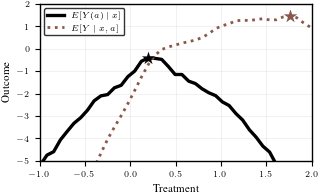

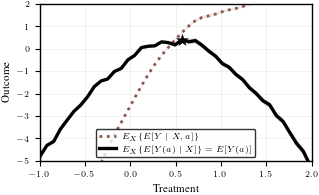

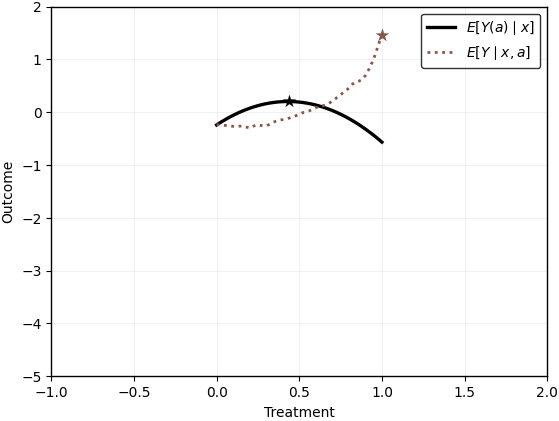

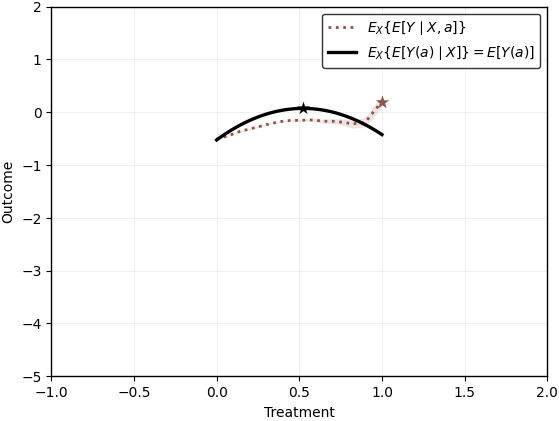

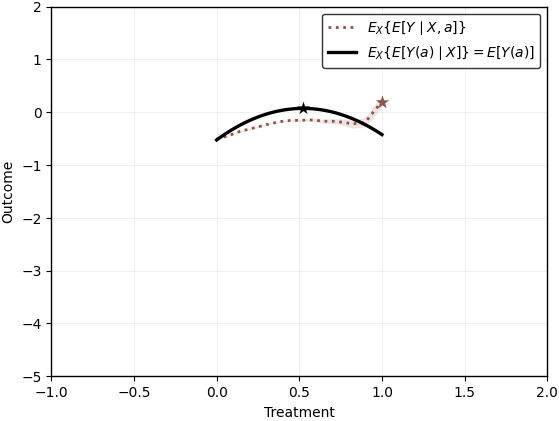

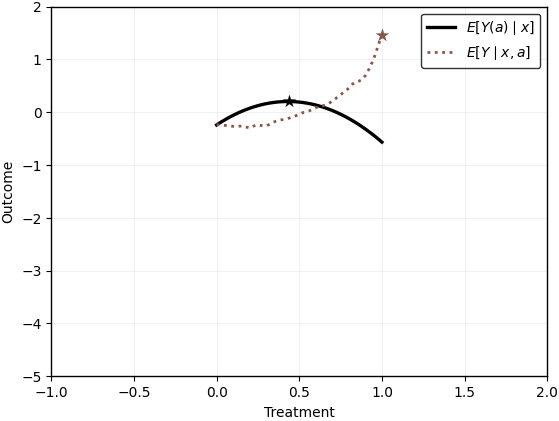

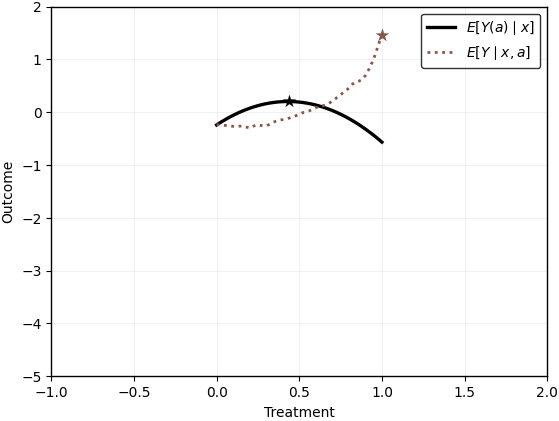

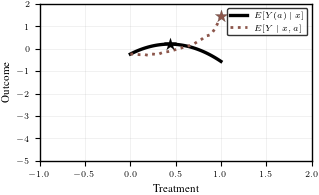

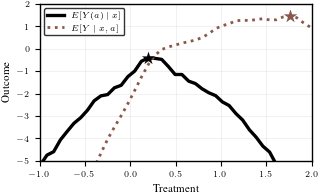

In [24]:
patient_curves_df, patient_metadata_df = patient_reference_curves(PATIENT_ID)
display(patient_metadata_df)
display(optimum_table(patient_curves_df))

from tueplots import bundles
with plt.rc_context(bundles.icml2024(column='half')):
    fig, ax = plot_reference_curves(
        patient_curves_df,
        title=f"Patient-specific reference curves | patient_id={PATIENT_ID}",
        show_ground_truth=SHOW_GROUND_TRUTH,
        show_associational=SHOW_ASSOCIATIONAL,
        show_structural=SHOW_STRUCTURAL,
        show_legend=SHOW_LEGEND,
        legend_loc=LEGEND_LOC,
        legend_bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR,
        legend_ncol=LEGEND_NCOL,
        legend_frameon=LEGEND_FRAMEON,
    )
    plt.savefig(OUTPUT_DIR / f"patient_reference_curves_seed_{SEED}_patient_{PATIENT_ID}.png", dpi=300, bbox_inches="tight")
    plt.show()


## Population-Level Curves

The population curves are computed by explicitly averaging patient-specific curves over the selected split:

- $E[Y(a)] \approx n^{-1}\sum_i E[Y(a)\mid X=X_i]$
- $E_X\{E[Y\mid X,A=a]\} \approx n^{-1}\sum_i E[Y\mid X=X_i,A=a]$
- $E_X\{g_{struct}(a,X)\} \approx n^{-1}\sum_i g_{struct}(a,X_i)$

In [25]:
population_curves_df = population_reference_curves(POPULATION_N)

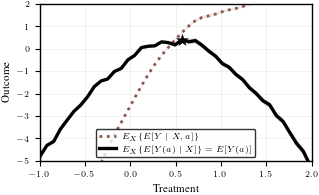

,curve,optimal_treatment,optimal_value
0,"$E_X\{E[Y\mid X,a]\}$",2.356990,3.229729
1,$E_X\{E[Y(a)\mid X]\}=E[Y(a)]$,0.569201,0.398021
2,"$E_X\{g_{struct}(a,X)\}$",0.643692,0.340169


In [26]:

with plt.rc_context(bundles.icml2024(column='half')):
    fig, ax = plot_reference_curves(
        population_curves_df,
        title="Population reference curves",
        show_ground_truth=SHOW_GROUND_TRUTH,
        show_associational=SHOW_ASSOCIATIONAL,
        show_structural=SHOW_STRUCTURAL,
        show_legend=SHOW_LEGEND,
        legend_loc=LEGEND_LOC,
        legend_bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR,
        legend_ncol=LEGEND_NCOL,
        legend_frameon=LEGEND_FRAMEON,
    )
    plt.savefig(OUTPUT_DIR / f"population_reference_curves_seed_{SEED}.png", dpi=300, bbox_inches="tight")
    plt.show()
optimum_table(population_curves_df)


## Optional: Save Tables

Uncomment the lines below if you want CSV versions of the curves.

In [27]:
# patient_curves_df.to_csv(OUTPUT_DIR / f"patient_reference_curves_seed_{SEED}_patient_{PATIENT_ID}.csv", index=False)
# patient_metadata_df.to_csv(OUTPUT_DIR / f"patient_metadata_seed_{SEED}_patient_{PATIENT_ID}.csv", index=False)
# population_curves_df.to_csv(OUTPUT_DIR / f"population_reference_curves_seed_{SEED}.csv", index=False)

## Semi-Synthetic TCGA Diagnostics

The following cells repeat the same diagnostic plots for the semi-synthetic TCGA dataset, using the dataset values from `configs/results/default_semisynthetic_results.json`.


In [28]:
import json

from tueplots import bundles

from src.hparam_search import set_config_value

SEMISYNTHETIC_RESULTS_CONFIG = PROJECT_ROOT / "configs" / "results" / "default_semisynthetic_results.json"
SEMISYNTHETIC_SPLIT = "test"
SEMISYNTHETIC_PATIENT_ID = 0
SEMISYNTHETIC_POPULATION_N = None  # Use None for all rows in the selected split.


def _flatten_nested_mapping(prefix: str, value: object, out: dict[str, object]) -> None:
    if isinstance(value, dict):
        for key, child in value.items():
            next_prefix = f"{prefix}.{key}" if prefix else str(key)
            _flatten_nested_mapping(next_prefix, child, out)
    else:
        out[prefix] = value


def _apply_nested_mapping(config: ExperimentConfig, values: dict[str, object]) -> None:
    flat: dict[str, object] = {}
    _flatten_nested_mapping("", values, flat)
    for dotted_path, value in flat.items():
        set_config_value(config, dotted_path, value)


semisynthetic_payload = json.loads(SEMISYNTHETIC_RESULTS_CONFIG.read_text(encoding="utf-8-sig"))
semisynthetic_config = ExperimentConfig()
_apply_nested_mapping(semisynthetic_config, semisynthetic_payload["config"])

semisynthetic_simulator = make_simulator(semisynthetic_config.data)
semisynthetic_train_sample, semisynthetic_test_sample = semisynthetic_simulator.sample_train_test(
    seed=int(semisynthetic_config.seed)
)
semisynthetic_sample = semisynthetic_train_sample if SEMISYNTHETIC_SPLIT == "train" else semisynthetic_test_sample
semisynthetic_treatment_grid = np.asarray(semisynthetic_simulator.policy_grid, dtype=float).reshape(-1)

print(f"Dataset: {semisynthetic_config.data.version} | structure: {semisynthetic_config.data.structure_type}")
print(f"Support: {semisynthetic_simulator.support}")
print(f"Selected split: {SEMISYNTHETIC_SPLIT} | n={semisynthetic_sample.covariates.shape[0]}")
print(f"Treatment grid points: {semisynthetic_treatment_grid.shape[0]}")
print(f"Config: {SEMISYNTHETIC_RESULTS_CONFIG}")


Dataset: semisynthetic_tcga | structure: v1
Support: (0.0, 1.0)
Selected split: test | n=1000
Treatment grid points: 51
Config: C:\Users\Alex\CODE\optimal_treatment_proximal_inference\weighted_proximal_oosr\configs\results\default_semisynthetic_results.json


In [29]:
def _semisynthetic_sample_vector(name: str, patient_id: int) -> float:
    value = getattr(semisynthetic_sample, name)
    return float(np.asarray(value).reshape(-1)[patient_id])


def _semisynthetic_structural_curve_for_x(x_row: np.ndarray, treatment_grid: np.ndarray) -> np.ndarray:
    x_rep = np.repeat(np.asarray(x_row, dtype=float).reshape(1, -1), len(treatment_grid), axis=0)
    zero_w = np.zeros((len(treatment_grid), int(semisynthetic_config.data.dim_w)), dtype=float)
    zero_u = np.zeros((len(treatment_grid), 2), dtype=float)
    return np.asarray(
        semisynthetic_simulator._do_outcome(
            np.asarray(treatment_grid, dtype=float).reshape(-1),
            x_rep,
            zero_w,
            zero_u,
            eps_y=0.0,
        ),
        dtype=float,
    ).reshape(-1)


def semisynthetic_patient_reference_curves(patient_id: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    x_row = semisynthetic_sample.covariates[patient_id]
    causal_grid, causal = semisynthetic_simulator.causal_curve_given_x_mc(
        x_row,
        grid=semisynthetic_treatment_grid,
        n_mc_samples=semisynthetic_config.data.tcga_causal_mc_samples_per_x,
    )
    (
        assoc_grid,
        associational,
        bin_counts,
        low_count_mask,
        empty_bin_mask,
        empty_fallback_treatment,
        empty_fallback_outcome,
        associational_method,
    ) = semisynthetic_simulator.associational_curve_given_x(
        x_row,
        grid=semisynthetic_treatment_grid,
        n_mc_samples=semisynthetic_config.data.associational_mc_samples,
    )
    causal_grid = np.asarray(causal_grid, dtype=float).reshape(-1)
    assoc_grid = np.asarray(assoc_grid, dtype=float).reshape(-1)
    if not np.allclose(causal_grid, assoc_grid):
        raise RuntimeError("Causal and associational curves were evaluated on different treatment grids.")
    structural = _semisynthetic_structural_curve_for_x(x_row, causal_grid)
    curves = pd.concat(
        [
            pd.DataFrame({"patient_id": patient_id, "treatment": causal_grid, "value": np.asarray(causal, dtype=float).reshape(-1), "curve_type": "ground_truth_causal"}),
            pd.DataFrame({"patient_id": patient_id, "treatment": assoc_grid, "value": np.asarray(associational, dtype=float).reshape(-1), "curve_type": "associational"}),
            pd.DataFrame({"patient_id": patient_id, "treatment": causal_grid, "value": structural, "curve_type": "structural"}),
        ],
        ignore_index=True,
    )
    metadata = pd.DataFrame(
        [
            {
                "split": SEMISYNTHETIC_SPLIT,
                "patient_id": patient_id,
                "observed_treatment": _semisynthetic_sample_vector("treatment", patient_id),
                "observed_outcome": _semisynthetic_sample_vector("outcome", patient_id),
                "optimal_treatment": _semisynthetic_sample_vector("optimal_treatment", patient_id),
                "assignment_mean": _semisynthetic_sample_vector("assignment_mean", patient_id),
                "associational_method": associational_method,
                "min_associational_count": int(np.nanmin(bin_counts)),
                "n_low_count_associational_points": int(np.sum(low_count_mask)),
                "n_empty_associational_points": int(np.sum(empty_bin_mask)),
            }
        ]
    )
    return curves, metadata


def semisynthetic_population_reference_curves(n_patients: int | None = None) -> pd.DataFrame:
    x_eval = semisynthetic_sample.covariates if n_patients is None else semisynthetic_sample.covariates[:n_patients]
    patient_curves = []
    for patient_id in range(len(x_eval)):
        curves_i, _ = semisynthetic_patient_reference_curves(patient_id)
        patient_curves.append(curves_i)
    curves = pd.concat(patient_curves, ignore_index=True)
    grouped = curves.groupby(["curve_type", "treatment"], as_index=False)["value"]
    population = grouped.agg(value="mean", std="std", n="count")
    z_975 = 1.959963984540054
    se = population["std"].fillna(0.0) / np.sqrt(population["n"].clip(lower=1))
    population["ci_lower"] = population["value"] - z_975 * se
    population["ci_upper"] = population["value"] + z_975 * se
    population["curve_type"] = "population_" + population["curve_type"]
    return population


### Semi-Synthetic TCGA Patient-Specific Curves


In [30]:
semisynthetic_patient_curves_df, semisynthetic_patient_metadata_df = semisynthetic_patient_reference_curves(
    SEMISYNTHETIC_PATIENT_ID
)
display(semisynthetic_patient_metadata_df)
display(optimum_table(semisynthetic_patient_curves_df))

,split,patient_id,observed_treatment,observed_outcome,optimal_treatment,assignment_mean,associational_method,min_associational_count,n_low_count_associational_points,n_empty_associational_points
0,test,0,0.666867,0.156178,0.376814,0.688476,kernel,2,7,0


,curve,optimal_treatment,optimal_value
0,$E[Y(a)\mid x]$,0.44,0.203097
1,"$E[Y\mid x,a]$",1.00,1.459647
2,"$g_{struct}(a,x_i)$: outcome without hidden-confounding term",0.42,0.276993


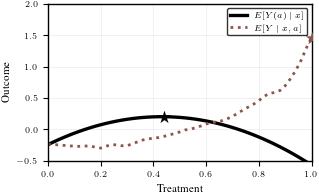

In [34]:
with plt.rc_context(bundles.icml2024(column='half')):
    fig, ax = plot_reference_curves(
        semisynthetic_patient_curves_df,
        title=f"Semi-synthetic TCGA patient-specific reference curves | patient_id={SEMISYNTHETIC_PATIENT_ID}",
        show_ground_truth=SHOW_GROUND_TRUTH,
        show_associational=SHOW_ASSOCIATIONAL,
        show_structural=SHOW_STRUCTURAL,
        show_legend=SHOW_LEGEND,
        legend_loc=LEGEND_LOC,
        legend_bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR,
        legend_ncol=LEGEND_NCOL,
        legend_frameon=LEGEND_FRAMEON,
    )
    ax.set_ylim([-0.5, 2])
    ax.set_xlim([-0.0, 1.0])
    plt.savefig(OUTPUT_DIR / f"semisynthetic_patient_reference_curves_seed_{semisynthetic_config.seed}_patient_{SEMISYNTHETIC_PATIENT_ID}.png", dpi=300, bbox_inches="tight")
    plt.show()


### Semi-Synthetic TCGA Population Curves


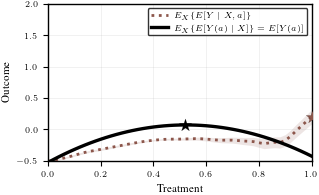

In [35]:
semisynthetic_population_curves_df = semisynthetic_population_reference_curves(SEMISYNTHETIC_POPULATION_N)
with plt.rc_context(bundles.icml2024(column='half')):
    fig, ax = plot_reference_curves(
        semisynthetic_population_curves_df,
        title="Semi-synthetic TCGA population reference curves",
        show_ground_truth=SHOW_GROUND_TRUTH,
        show_associational=SHOW_ASSOCIATIONAL,
        show_structural=SHOW_STRUCTURAL,
        show_legend=SHOW_LEGEND,
        legend_loc=LEGEND_LOC,
        legend_bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR,
        legend_ncol=LEGEND_NCOL,
        legend_frameon=LEGEND_FRAMEON,
    )
    ax.set_ylim([-0.5, 2])
    ax.set_xlim([-0.0, 1.0])
    plt.savefig(OUTPUT_DIR / f"semisynthetic_population_reference_curves_seed_{semisynthetic_config.seed}.png", dpi=300, bbox_inches="tight")
    plt.show()


In [33]:

display(optimum_table(semisynthetic_population_curves_df))


,curve,optimal_treatment,optimal_value
0,"$E_X\{E[Y\mid X,a]\}$",1.00,0.201989
1,$E_X\{E[Y(a)\mid X]\}=E[Y(a)]$,0.52,0.072182
2,"$E_X\{g_{struct}(a,X)\}$",0.52,0.088427
